## Fork-Join Trees: Compositions on Hierarchical Applications

`1_method_synthetic.ipynb` builds the method on chains of services: one GP per service, node bounds, and compositions of
the node bounds into an end-to-end bound. This notebook applies the same models and compositions to applications in
which a service merges the results of two others, structured as trees (experiment B3 of `new_experiments.md`). It is
structured as follows:

1. **Setup (Section 1):** the three synthetic services, their training data and their GPs, exactly as in
   `1_method_synthetic.ipynb` (same seed, so the GPs are the same).
2. **Fork-join trees (Section 2):** why the latency of a tree is the maximum over its leaf-to-root paths, every
   composition applied path by path, and its coverage and tightness against the simulated trees.

References such as 6e or 7a are sections of `1_method_synthetic.ipynb`, where every node bound and composition is
derived. The tree topologies are in `pegasus/trees.py`, the tree simulator is `simulate_tree` in `pegasus/simulation.py`.

## 1. Setup: Services, Training Data and GPs

The parameters below are those of the first cell of `1_method_synthetic.ipynb`, restricted to what this notebook uses:
the violation probability $\varepsilon$ (`alpha`), the arrival process, the correlation of an item's execution-time noise
across services, the simulated items per run, the confidence level $\gamma$ of the pessimistic mean (6b), and the
confidence interval of a measured quantile (6f). The next cells reproduce Sections 1a and 2 of that notebook: the mean
execution time of every service type as a function of CPU and quality (`true_demand`), 50 noisy training measurements
per service, and one GP per service on CPU and quality. The global seed is set first, so the training data and the GPs
are identical to those of `1_method_synthetic.ipynb`. The arrival rate of that notebook is not used: Section 2 sets it
per configuration.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.stats import norm

from pegasus.baselines import joint_gaussian_quantile, queueing_formula_latency
from pegasus.baselines_chain import independent_snc_convolution
from pegasus.bounds import martingale_closed_form_node_bound, network_service_bound
from pegasus.data import WORKERS_COLUMN, model_inputs
from pegasus.service_gp import execution_time_belief, train_gp_models
from pegasus.simulation import fifo_chain_latencies, quantile_with_lower_bound, simulate_tree
from pegasus.trees import balanced_tree, leaf_to_root_paths, max_over_paths, max_path_sum, narrow_tree

# Set global seed for reproducibility (as in 1_method_synthetic.ipynb, so that the training data and GPs are the same)
np.random.seed(35)

# Violation probability epsilon of every bound: a bound at alpha is a bound on the (1 - alpha) latency quantile
alpha = 0.05
z_score = norm.ppf(1 - alpha)
p_str = f"{(1 - alpha) * 100:.2f}".rstrip('0').rstrip('.')   # percentile label, e.g. '95'

# Workload and ground truth (the arrival rate is set per configuration in Section 2)
arrival_process = "poisson"   # "poisson" or "periodic", as in 1_method_synthetic.ipynb
arrival_jitter = 0.2          # relative half-width of the uniform jitter on periodic gaps, in [0, 1)
item_correlation = 0.7        # correlation of an item's execution-time noise across services (a large item is slow everywhere)
n_sim_items = 5000            # items per simulated run of the ground truth
arrival_name = "Poisson" if arrival_process == "poisson" else f"periodic (±{arrival_jitter:.0%} jitter)"   # named in every conclusion

# Belief and evaluation
confidence = 0.95        # the pessimistic mean of every bound lies above the true mean with this probability (6b)
coverage_check = dict(n_batches=10, confidence=0.95)   # confidence interval of a measured quantile (batch means), see 6f

# Formatting of conclusions that are rendered from the results
pct = lambda value: f"{value:.0%}"
ratio = lambda value: f"{value:.2f}×"


def span(values, fmt):
    # "between a and b", or just "a" if both round to the same text
    low, high = fmt(np.min(values)), fmt(np.max(values))
    return low if low == high else f"between {low} and {high}"

In [2]:
def true_demand(x, service_type):
    """Simulates latency demand d(x) = f(cpu, quality, parallelism). The parallelism is the number of workers of the
    service; CPU is the CPU of one worker, so the parallelism does not change the execution time of an item."""
    cpu, quality, parallelism = x[:, 0], x[:, 1], x[:, 2]
    if service_type == "type_A":
        return 0.010 + 0.040 / cpu + 0.030 * (quality ** 2.0)
    elif service_type == "type_B":
        return 0.012 + 0.035 / cpu + 0.025 * (quality ** 1.5)
    else:
        return 0.008 + 0.030 / cpu + 0.020 * (quality ** 1.8)

n_train = 50
X_train = np.column_stack([
    np.random.uniform(0.5, 2.0, n_train),  # CPU
    np.random.uniform(0.5, 2.0, n_train),  # Quality
    np.floor(np.random.uniform(1.0, 5.0, n_train))  # Parallelism: workers of every service, 1 to 4
])

service_names = ["s1", "s2", "s3"]
service_types = ["type_A", "type_B", "type_C"]
y_train_dict = {}

# Standard deviation of the execution-time noise per service (s)
noise_levels = {
    "s1": 0.0060,  # high variance
    "s2": 0.0010,  # low variance (stable)
    "s3": 0.0035   # medium variance
}

for s_name, s_type in zip(service_names, service_types):
    y_clean = true_demand(X_train, s_type)
    noise = np.random.normal(0, noise_levels[s_name], n_train)
    y_train_dict[s_name] = y_clean + noise

print("Training dataset successfully generated.")

Training dataset successfully generated.


In [3]:
def inputs_of(x_cfgs):
    # Inputs of every GP: CPU and quality, without the parallelism (as inputs_of in 1_method_synthetic.ipynb)
    return model_inputs(np.atleast_2d(x_cfgs), WORKERS_COLUMN)


gp_models = train_gp_models(inputs_of(X_train), y_train_dict, service_names)
print("Trained GP models for all microservices.")

Trained GP models for all microservices.


/home/boris/development/composable-autonomous-offerings/.venv/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


## 2. Fork-Join Trees

`1_method_synthetic.ipynb` composes chains (Sections 7–9). This section asks whether the compositions also hold for a hierarchical application in
which results are merged (experiment B3 of `new_experiments.md`), and how their tightness changes with the size of the
hierarchy.

**The application.** A tree of services: the leaves (detectors) alternate between $s_1$ and $s_2$, and every inner
service, including the root, is the aggregator $s_3$. An arriving frame (item) is sent to all leaves at the same moment.
An aggregator waits until both of its children have released the frame (the frame is then *complete* at the
aggregator), and processes the complete frames in the order of their arrival (FIFO). One frame is therefore one item at
every service, and every service receives the same arrival rate $\lambda$. The end-to-end latency of a frame is the time
from its arrival until the root releases it.

**The hierarchies.** A *balanced* tree with $h$ levels has $N = 2^h - 1$ services and $P = 2^{h-1}$ paths from a leaf
to the root, each with $h$ services; we use $h = 1$ to $8$ (`tree_levels`). A *narrow* tree with $h$ levels has a chain
of $h - 1$ aggregators, each joining the one below it with one new leaf: the same longest path of $h$ services, but only
$N = 2h - 1$ services and $P = h$ paths; we use $h = 5$ to $8$ (`narrow_levels`). Comparing the two at the same $h$
separates the effect of depth from that of breadth.

**Workload.** As in B3, the arrival rate is set per configuration to 50% utilization of the slowest service,
$\lambda = 0.5\,\min_k c_k / m_k$, where $m_k$ is the true mean execution time of service $k$ (s) and $c_k$ its number of
workers. The fixed rate of Sections 6–9 (`arrival_rate`) would overload some configurations, because every service of
a tree receives the full rate. The bounds receive $\lambda$ as known (Assumption 5 of the paper). The arrival process,
the correlation of an item's execution times across services (`item_correlation`) and $\varepsilon$ are those of the
setup cell (Section 1). There are two versions:
- *one worker* per service: the single-server FIFO services of the paper (Assumption 2);
- *1 to 4 workers* per service, drawn uniformly for every service and configuration (`max_workers`, the range of the
  parallelism of the training data, Section 1).

The section is structured as follows:

- **2a. Reduction to paths:** why the latency of a tree is the maximum over its paths, each run as a chain; checked
  on the simulation.
- **2b. Union bound over paths, propagated martingale nodes:** the node bounds of 6e on every path.
- **2c. Union bound over nodes, martingale nodes:** every service of the tree at $\varepsilon / N$, longest path (the
  DAG rule of 7a).
- **2d. Network service curve per path, Hölder:** 7b on every path.
- **2e. Independent SNC convolution per path (baseline):** 7c on every path.
- **2f. Joint Gaussian quantile per path (baseline):** 7c without a queue.
- **2g. Queueing formula per service (baseline):** the Allen-Cunneen approximation, added along every path.
- **2h. Oracle: measured nodes, union bound:** 2c with the measured node latencies.
- **2i. Results:** coverage and tightness over the number of levels.

The setup cell below draws the held-out configurations and simulates every tree in both versions; every subsection adds
its end-to-end latency per configuration to `tree_results`, and 2i compares them. Coverage is checked as in 6f.

In [4]:
# Setup of Section 2: held-out configurations, the trees (pegasus/trees.py), and the simulated ground truth of every tree
# in both versions (simulate_tree in pegasus/simulation.py). Every subsection below adds its end-to-end latency per
# configuration to tree_results[(version, shape, levels)].
n_cfg_tree = 100
max_workers = 4                  # largest number of workers of a service, the range of the parallelism in Section 1a
tree_levels = range(1, 9)        # balanced trees: levels h
narrow_levels = range(5, 9)      # narrow trees: levels h
identity_max_services = 63       # 2a replays the paths of trees up to this size; the execution times of larger ones do not fit in memory
rng_tree = np.random.default_rng(13)   # own random generator, so that no other result changes

# Configurations shared by all services of a tree (the global-quality assumption of Section 9); the parallelism column
# is not used, the workers are drawn below
X_cfg_tree = np.column_stack([rng_tree.uniform(0.5, 2.0, n_cfg_tree), rng_tree.uniform(0.5, 2.0, n_cfg_tree), np.ones(n_cfg_tree)])
true_means_tree = {s_name: true_demand(X_cfg_tree, s_type) for s_name, s_type in zip(service_names, service_types)}
beliefs_tree = {s_name: execution_time_belief(gp_models[s_name], inputs_of(X_cfg_tree), confidence) for s_name in service_names}
lower_means_tree = {s_name: execution_time_belief(gp_models[s_name], inputs_of(X_cfg_tree), 1 - confidence)[0] for s_name in service_names}
predictions_tree = {s_name: gp_models[s_name].predict(inputs_of(X_cfg_tree), return_std=True) for s_name in service_names}

trees = {**{("balanced", h): balanced_tree(h) for h in tree_levels}, **{("narrow", h): narrow_tree(h) for h in narrow_levels}}
tree_versions = ["one worker", f"1 to {max_workers} workers"]
tree_runs, tree_results = {}, {}
for version in tree_versions:
    for (shape, levels), (children, services) in trees.items():
        n_services = len(services)
        workers = (np.ones((n_cfg_tree, n_services), dtype=int) if version == tree_versions[0]
                   else rng_tree.integers(1, max_workers + 1, (n_cfg_tree, n_services)))
        # 50% utilization of the slowest service: lambda = 0.5 * min_k c_k / m_k
        tree_workload = dict(process=arrival_process, rate=0.5 * np.min([workers[:, k] / true_means_tree[s] for k, s in enumerate(services)], axis=0),
                             jitter=arrival_jitter)
        replay = n_services <= identity_max_services
        simulated = simulate_tree(np.column_stack([true_means_tree[s] for s in services]), np.array([noise_levels[s] for s in services]),
                                  children, n_items=n_sim_items, item_correlation=item_correlation, rng=rng_tree, workers=workers,
                                  node_level=1 - alpha / n_services, return_execution=replay, **tree_workload)
        latencies, node_quantiles, paths = simulated[0], simulated[1], leaf_to_root_paths(children)
        gap = None
        if replay:   # 2a: every path run as a chain with the same arrivals and execution times
            arrivals, execution = simulated[2:]
            kept = slice(n_sim_items - latencies.shape[1], None)   # the frames after the warm-up, as in simulate_tree
            path_maximum = np.max([fifo_chain_latencies(arrivals, execution[:, :, path], workers[:, path])[1][:, kept] for path in paths], axis=0)
            gap = ((latencies - path_maximum).min(), (latencies - path_maximum).max())
            del arrivals, execution, simulated
        measured, measured_low = quantile_with_lower_bound(latencies, 1 - alpha, **coverage_check)
        tree_runs[(version, shape, levels)] = dict(services=services, paths=paths, workers=workers, workload=tree_workload, measured=measured,
                                                   measured_low=measured_low, node_quantiles=node_quantiles, gap=gap)
        tree_results[(version, shape, levels)] = {}
print(f"Simulated {len(tree_runs)} trees ({len(trees)} per version) at {n_cfg_tree} configurations each.")

Simulated 24 trees (12 per version) at 100 configurations each.


### 2a. Reduction to Paths

At a service with one worker, frame $j$ is released at $R(j) = \max\big(C(j),\, R(j-1)\big) + Y(j)$, where $C(j)$ is the
time at which frame $j$ is complete at the service (its arrival time at a leaf; the later of the two release times of
the children at an aggregator), $R(j-1)$ the release time of the frame before it, and $Y(j)$ the execution time of
frame $j$ at the service (all in s). For example, if the children of an aggregator release frame $j$ at 30 ms and
42 ms, the aggregator releases frame $j-1$ at 45 ms, and $Y(j)$ = 8 ms, then $C(j)$ = 42 ms and $R(j)$ = 45 + 8 = 53 ms.

These operations are only maxima and sums. Expanding the recursion from the root downwards, the release time at the
root is a maximum over sequences of (frame, service) steps of an arrival time plus the execution times along the
sequence. Every such sequence runs down one leaf-to-root path, and the sequences of one path give exactly the release
time that the root would have if this path were run as a separate chain with the same arrivals and execution times. So

$$D(j) = \max_p D_p(j),$$

where $D(j)$ is the end-to-end latency of frame $j$ in the tree and $D_p(j)$ its end-to-end latency through path $p$ run
as a chain. The wait for the other branch is contained in the maximum. If every path has a bound $d_p$ with
$P(D_p > d_p) \le \varepsilon / P$, then $P\big(D > \max_p d_p\big) \le \sum_p P(D_p > d_p) \le \varepsilon$ (union bound over
the paths), whatever the dependence between the paths, which share services and arrivals. Every composition of a chain
in Section 7 therefore extends to the tree, at $\varepsilon / P$ per path.

With several workers, a service gives every frame to the first free worker: frames can overtake each other, and which
worker serves a frame depends on the execution times of the frames before it. The release times are then no longer
maxima and sums along fixed sequences, and the reduction is not exact. The per-path compositions are then not proven
for trees, only checked by the simulation, as the network service curve with several workers (7b). The cell below
reports, over all frames, configurations and trees with up to `identity_max_services` services, how far the latency of
the tree lies from the maximum over its paths run as chains.

In [5]:
# Deviation of the tree's end-to-end latency from the maximum over its paths run as chains (2a), in seconds, over all
# frames, configurations and replayed trees of a version; both 0 means that the reduction is exact
path_reduction_gap = {}
for version in tree_versions:
    gaps = [run["gap"] for (v, _, _), run in tree_runs.items() if v == version and run["gap"] is not None]
    path_reduction_gap[version] = (min(low for low, _ in gaps), max(high for _, high in gaps))
    print(f"{version}: tree latency minus maximum over the path chains between {path_reduction_gap[version][0] * 1e3:+.2f} ms "
          f"and {path_reduction_gap[version][1] * 1e3:+.2f} ms ({len(gaps)} trees)")

one worker: tree latency minus maximum over the path chains between +0.00 ms and +0.00 ms (10 trees)
1 to 4 workers: tree latency minus maximum over the path chains between -290.57 ms and +201.95 ms (10 trees)


### 2b. Union Bound over Paths, Propagated Martingale Nodes

Path $p$ is a chain of $K_p$ services from its leaf to the root. As a chain it gets the union bound of 7a over its node
bounds, and the tree gets the maximum over the paths (2a): $\max_p \sum_{k \in p} d_k$. A frame violates this bound
only if, on some path, some service violates its node bound. There are $\sum_p K_p$ such (path, service) pairs, so every
node bound is computed at $\varepsilon / \sum_p K_p$ (in a balanced tree $\varepsilon / (P h)$). On a path, every service
except the leaf receives the departures of the service before it on that path (one of its children), so the
propagated spacing of 6e applies; an aggregator gets one node bound per child. It is a guarantee for any dependence
between the services, under the assumptions of 6e, for services with one worker (2a).

The node bound is the closed form of 6e (`martingale_closed_form_node_bound` in `pegasus/bounds.py`, which
`2_evaluation.ipynb` reports as "Pegasus per node"). It uses the same waiting-time tail as 6e, Kingman's
$e^{-\theta w}$ with the larger of the decay rates of 6d and of the spacing, and adds the own execution time in closed
form instead of over 4000 bins. It leaves out the Pollaczek-Khinchine refinement of 6d for Poisson arrivals, so it is
somewhat larger per node. The reason is the cost: the numerical bound bisects over the bins once per (service, child) pair, and the largest
tree (`tree_levels`) has as many such pairs as services, in both versions.

In [6]:
# Union bound over paths with propagated martingale nodes (closed form of 6e); every (path, service) pair at alpha / sum_p K_p
for key, run in tree_runs.items():
    services, workers = run["services"], run["workers"]
    epsilon_node = alpha / sum(len(path) for path in run["paths"])
    tree_results[key]["union bound over paths, propagated martingale nodes (6e, 7a)"] = max_path_sum(
        run["paths"], lambda k, previous: martingale_closed_form_node_bound(
            *beliefs_tree[services[k]], epsilon=epsilon_node, workers=workers[:, k],
            previous_lower_mean=None if previous is None else lower_means_tree[services[previous]],
            previous_var=None if previous is None else beliefs_tree[services[previous]][1],
            previous_workers=1 if previous is None else workers[:, previous], **run["workload"]))

### 2c. Union Bound over Nodes, Martingale Nodes (Ablation)

The DAG rule of 7a: every one of the $N$ services gets $\varepsilon / N$, and the bound is the longest path,
$\max_p \sum_{k \in p} d_k(\varepsilon / N)$. It needs no reduction to paths: the end-to-end latency of a frame is the
maximum over the paths of the sum of its latencies *in the tree* (release minus completion time at every service), so a
frame that violates the bound violates at least one of the $N$ node bounds. In a balanced tree, it splits $\varepsilon$
into fewer parts than 2b ($N = 2^h - 1$ against $P h = 2^{h-1} h$). In return, it has no propagated spacing: an
aggregator receives a frame when the *later* of its two children releases it, a spacing that 6e does not cover, so every
node bound assumes the external arrivals (Assumption 6 of the paper). The node bound is the closed form of 2b without a
service before it (the closed form of 6d).

In [7]:
# Union bound over nodes (every service at alpha / N, longest path) with martingale nodes (closed form of 6d)
for key, run in tree_runs.items():
    services, workers = run["services"], run["workers"]
    node_bounds_tree = [martingale_closed_form_node_bound(*beliefs_tree[s], epsilon=alpha / len(services), workers=workers[:, k], **run["workload"])
                        for k, s in enumerate(services)]
    tree_results[key]["union bound over nodes, martingale nodes (6d, 7a)"] = max_path_sum(run["paths"], lambda k, previous: node_bounds_tree[k])

### 2d. Network Service Curve per Path, Hölder

Every path gets the network service curve of 7b at $\varepsilon / P$, with tuned Hölder exponents, so it holds for any
dependence between the services of the path, including the correlated execution times of an item; the tree bound is
the maximum over the paths (2a). It is computed for the version with one worker only. With several workers it would
not be a proof either, since the network service curve assumes that items leave every service in order (7b), and it
is the most expensive composition: the exponents are tuned once per path, and with workers drawn per service no two
paths of a tree are alike. With one worker, paths with the same sequence of services have the same bound and are
computed once.

In [8]:
# Network service curve with tuned Hölder exponents per path (network_service_bound in pegasus/bounds.py), one worker only
for key, run in tree_runs.items():
    if key[0] != tree_versions[0]:
        continue
    services, workers, n_paths = run["services"], run["workers"], len(run["paths"])
    tree_results[key]["network service curve per path, Hölder (7b)"] = max_over_paths(
        run["paths"], lambda path: network_service_bound([beliefs_tree[services[k]] for k in path], epsilon=alpha / n_paths,
                                                         path_workers=[workers[:, k] for k in path], **run["workload"]),
        path_key=lambda path: tuple(services[k] for k in path))

### 2e. Independent SNC Convolution per Path (Baseline)

The independent SNC convolution of 7c on every path at $\varepsilon / P$, maximum over the paths: the network service
curve with all Hölder exponents equal to 1, which multiplies the node MGFs as if the services were independent. It is
the composition that `2_evaluation.ipynb` reports as "Pegasus SNC", where the execution times are independent between
services. Here they are correlated (`item_correlation`), so it is not a guarantee (7c). It is computed for both
versions; with one worker, paths with the same services are computed once.

In [9]:
# Independent SNC convolution per path (independent_snc_convolution in pegasus/baselines_chain.py)
for key, run in tree_runs.items():
    services, workers, n_paths = run["services"], run["workers"], len(run["paths"])
    tree_results[key]["independent SNC convolution per path (7c)"] = max_over_paths(
        run["paths"], lambda path: independent_snc_convolution([beliefs_tree[services[k]] for k in path], alpha / n_paths,
                                                               path_workers=[workers[:, k] for k in path], **run["workload"]),
        path_key=(lambda path: tuple(services[k] for k in path)) if key[0] == tree_versions[0] else None)

### 2f. Joint Gaussian Quantile per Path (Baseline)

The joint Gaussian quantile of 7c on every path: the $(1-\varepsilon)$ quantile of the sum of the execution times
predicted by the GPs along the path, as if they were independent, without any queue; the maximum over the paths. It is a
point prediction of the quantile of every path, so it is computed at $\varepsilon$, not $\varepsilon / P$ (as "GP Sum" in
`2_evaluation.ipynb`). Not a guarantee.

In [10]:
# Joint Gaussian quantile of the predicted execution times per path (joint_gaussian_quantile in pegasus/baselines.py)
for key, run in tree_runs.items():
    services = run["services"]
    tree_results[key]["joint Gaussian quantile per path (7c)"] = max_over_paths(
        run["paths"], lambda path: joint_gaussian_quantile([predictions_tree[services[k]][0] for k in path],
                                                           [predictions_tree[services[k]][1] for k in path], z_score),
        path_key=lambda path: tuple(services[k] for k in path))

### 2g. Queueing Formula per Service (Baseline)

The textbook approach: per service, the $(1-\varepsilon)$ latency quantile of a queue with $c$ workers from the
Allen-Cunneen approximation of the mean wait (Kingman's formula for one worker) and an exponential waiting time, with
the mean and variance of the execution time predicted by the GP (`queueing_formula_latency` in `pegasus/baselines.py`).
The quantiles are added along every path, and the tree gets the maximum over the paths. Every service is assumed to
receive the external arrivals. An approximation, not a bound (as "Allen-Cunneen" in `2_evaluation.ipynb`).

In [11]:
# Allen-Cunneen latency quantile per service, added along every path (queueing_formula_latency in pegasus/baselines.py)
for key, run in tree_runs.items():
    services, workers = run["services"], run["workers"]
    formula_quantiles = [queueing_formula_latency(predictions_tree[s][0], predictions_tree[s][1] ** 2, epsilon=alpha, workers=workers[:, k],
                                                  **run["workload"]) for k, s in enumerate(services)]
    tree_results[key]["queueing formula per service, Allen-Cunneen"] = max_path_sum(run["paths"], lambda k, previous: formula_quantiles[k])

### 2h. Oracle: Measured Nodes, Union Bound

2c with measured node latencies in place of the node bounds: the $(1 - \varepsilon / N)$ quantile of the latency of
every service in the tree (release minus completion time), measured in the simulation of the setup cell, added along
every path, maximum over the paths. It shows what the union bound over nodes costs without any model error, as the
oracle of Section 9. It is a reference, not a method: it needs measurements of the composition itself.

In [12]:
# Measured node quantiles at 1 - alpha / N (setup cell), added along the longest path
for key, run in tree_runs.items():
    tree_results[key]["oracle: measured nodes, union bound (7a)"] = max_path_sum(run["paths"], lambda k, previous: run["node_quantiles"][:, k])

### 2i. Results

**The figure** has one row per version (top: one worker per service; bottom: workers drawn per service) and two panels
per row, both over the number of levels $h$ of the tree.
- *Left, coverage:* the share of the held-out configurations that a method does not miss (6f). The dotted line is the
  confidence level $\gamma$ (6b), the target of the guarantees (2b–2d); the baselines are not built to reach it.
- *Right, tightness:* the median over the configurations of the method's latency ÷ the measured quantile, on a
  logarithmic axis. A value of 1 would be exact; below 1, the median prediction lies under the measured quantile.

Solid lines with filled markers are balanced trees; dashed lines with hollow markers are narrow trees of the same
depth. Look at how fast each line grows with $h$, and at the gap between the solid and the dashed line of a method at
the same $h$: the narrow tree has the same depth but far fewer paths and services, so the gap is the cost of breadth.
The conclusion below the figure is rendered from the same results.

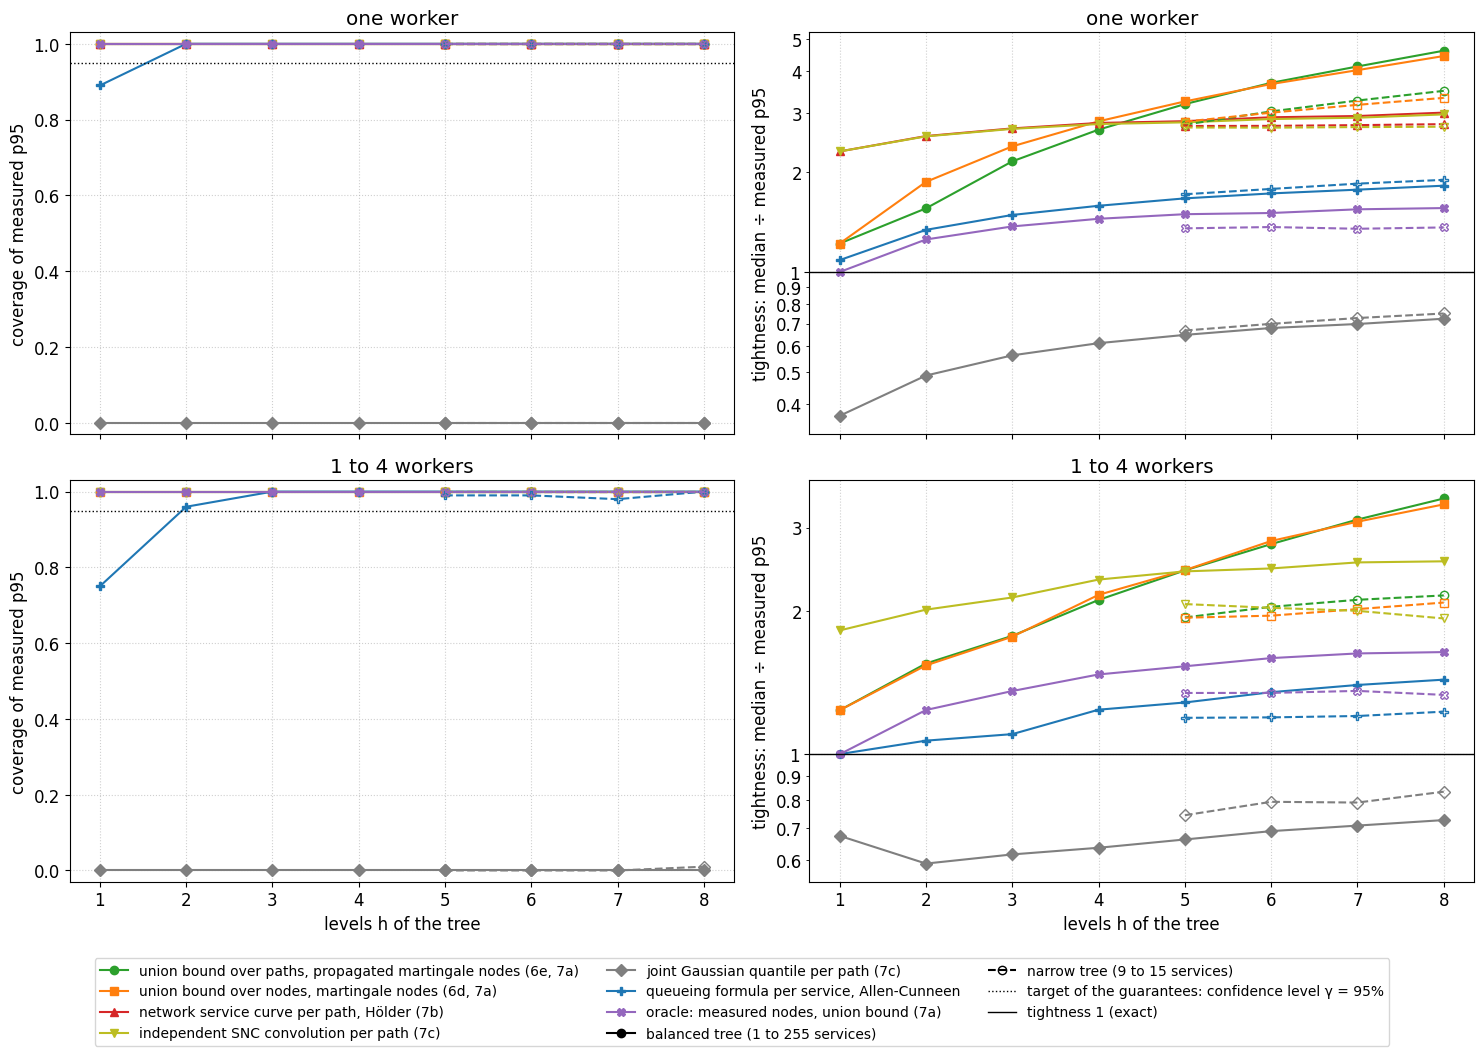

In [13]:
# Coverage and tightness of the methods of 2b-2h over the levels h (source: tree_results and tree_runs of this section)
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

plt.style.use('default')
plt.rcParams.update({'font.size': 12})
tree_method_styles = {   # color and marker per method: guarantees first, then baselines, then the oracle
    "union bound over paths, propagated martingale nodes (6e, 7a)": ("tab:green", "o"),
    "union bound over nodes, martingale nodes (6d, 7a)": ("tab:orange", "s"),
    "network service curve per path, Hölder (7b)": ("tab:red", "^"),
    "independent SNC convolution per path (7c)": ("tab:olive", "v"),
    "joint Gaussian quantile per path (7c)": ("tab:gray", "D"),
    "queueing formula per service, Allen-Cunneen": ("tab:blue", "P"),
    "oracle: measured nodes, union bound (7a)": ("tab:purple", "X"),
}
tree_coverage = lambda key, name: np.mean(tree_results[key][name] >= tree_runs[key]["measured_low"])
tree_tightness = lambda key, name: np.median(tree_results[key][name] / tree_runs[key]["measured"])
size_range = lambda shape, levels: f"{len(trees[(shape, min(levels))][1])} to {len(trees[(shape, max(levels))][1])} services"

fig, axes = plt.subplots(2, 2, figsize=(15, 9.6), sharex=True)
handles = {}
for row, version in zip(axes, tree_versions):
    for shape, levels, linestyle, filled in (("balanced", tree_levels, "-", True), ("narrow", narrow_levels, "--", False)):
        for name, (color, marker) in tree_method_styles.items():
            if name not in tree_results[(version, shape, min(levels))]:
                continue   # 2d: one worker only
            for ax, metric in zip(row, (tree_coverage, tree_tightness)):
                line, = ax.plot(list(levels), [metric((version, shape, h), name) for h in levels], linestyle=linestyle, marker=marker,
                                color=color, markerfacecolor=color if filled else "none", linewidth=1.5)
            handles.setdefault(name, line)
    row[0].axhline(confidence, color="black", linestyle=":", linewidth=1)
    row[1].axhline(1.0, color="black", linewidth=1)
    row[0].set_ylim(-0.03, 1.03)
    row[0].set_ylabel(f"coverage of measured p{p_str}")
    row[1].set_ylabel(f"tightness: median ÷ measured p{p_str}")
    row[1].set_yscale("log")
    for axis in (row[1].yaxis.set_major_formatter, row[1].yaxis.set_minor_formatter):   # plain ratios instead of powers of ten
        axis(FuncFormatter(lambda value, _: f"{value:g}"))
    for ax in row:
        ax.set_title(version)
        ax.grid(True, linestyle=":", alpha=0.6)
for ax in axes[1]:
    ax.set_xlabel("levels h of the tree")
    ax.set_xticks(list(tree_levels))
handles[f"balanced tree ({size_range('balanced', tree_levels)})"] = Line2D([], [], color="black", linestyle="-", marker="o")
handles[f"narrow tree ({size_range('narrow', narrow_levels)})"] = Line2D([], [], color="black", linestyle="--", marker="o", markerfacecolor="none")
handles[f"target of the guarantees: confidence level γ = {confidence:.0%}"] = Line2D([], [], color="black", linestyle=":", linewidth=1)
handles["tightness 1 (exact)"] = Line2D([], [], color="black", linewidth=1)
fig.legend(handles.values(), handles.keys(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=10)
plt.tight_layout()
plt.show()

In [14]:
paths_rule, nodes_rule = "union bound over paths, propagated martingale nodes (6e, 7a)", "union bound over nodes, martingale nodes (6d, 7a)"
holder_rule, independent_rule = "network service curve per path, Hölder (7b)", "independent SNC convolution per path (7c)"
formula_rule, gaussian_rule, oracle_rule = "queueing formula per service, Allen-Cunneen", "joint Gaussian quantile per path (7c)", "oracle: measured nodes, union bound (7a)"
low_h, high_h, narrow_h = min(tree_levels), max(tree_levels), max(narrow_levels)


def version_summary(version):
    keys = [key for key in tree_runs if key[0] == version]
    balanced = lambda h: (version, "balanced", h)
    tight = lambda name, key: ratio(tree_tightness(key, name))
    over_depth = lambda name: f"{tight(name, balanced(low_h))} at h = {low_h}, {tight(name, balanced(high_h))} at h = {high_h}"
    coverages = lambda name: [tree_coverage(key, name) for key in keys]
    guarantees = [name for name in (paths_rule, nodes_rule, holder_rule) if name in tree_results[keys[0]]]
    network_rule = holder_rule if holder_rule in guarantees else independent_rule
    network_tighter = [h for h in tree_levels if tree_tightness(balanced(h), network_rule) < tree_tightness(balanced(h), paths_rule)]
    nodes_tighter = [h for h in tree_levels if tree_tightness(balanced(h), nodes_rule) < tree_tightness(balanced(h), paths_rule)]
    levels_text = lambda hs: f"h = {', '.join(map(str, hs))}" if hs else "no number of levels"
    low_gap, high_gap = path_reduction_gap[version]
    reduction = ("exact for every frame" if low_gap == high_gap == 0 else
                 f"the tree latency lies between {low_gap * 1e3:+.2f} ms and {high_gap * 1e3:+.2f} ms from the maximum over its path chains")
    network_label = network_rule + ("" if network_rule == holder_rule else " (no guarantee under correlation)")
    return (
        f"- **{version}.** Reduction to paths (2a): {reduction}. The lowest coverage of the guarantees (2b–2d) over all trees is "
        f"{pct(min(min(coverages(name)) for name in guarantees))}.\n"
        f"  - {paths_rule}: {over_depth(paths_rule)}; {tight(paths_rule, (version, 'narrow', narrow_h))} for the narrow tree with h = {narrow_h}.\n"
        f"  - {nodes_rule}: {over_depth(nodes_rule)}; tighter than the union bound over paths at {levels_text(nodes_tighter)}.\n"
        f"  - {network_label}: {over_depth(network_rule)}, coverage {span(coverages(network_rule), pct)}; tighter than the union bound "
        f"over paths at {levels_text(network_tighter)}.\n"
        + (f"  - {independent_rule} (no guarantee under correlation): {over_depth(independent_rule)}, coverage {span(coverages(independent_rule), pct)}.\n"
           if network_rule != independent_rule else "")
        + f"  - {formula_rule} (no guarantee): coverage {span(coverages(formula_rule), pct)}, "
        f"{pct(tree_coverage(balanced(low_h), formula_rule))} for a single service; tightness {over_depth(formula_rule)}.\n"
        f"  - {gaussian_rule} (no queue): coverage {span(coverages(gaussian_rule), pct)}, tightness {over_depth(gaussian_rule)}.\n"
        f"  - {oracle_rule}: {over_depth(oracle_rule)}.\n")


display(Markdown(
    f"**What this shows** ({arrival_name} arrivals at 50% utilization of the slowest service, item correlation {item_correlation:g}, "
    f"{n_cfg_tree} held-out configurations per tree; balanced trees with h = {low_h} to {high_h} levels ({size_range('balanced', tree_levels)}), "
    f"narrow trees with h = {min(narrow_levels)} to {narrow_h}; tightness is the median of method ÷ measured p{p_str}).\n"
    + "".join(version_summary(version) for version in tree_versions)
    + "\nA union bound over nodes pays for every service it adds, so its tightness grows with the number of services on a path "
    "and, through $\\varepsilon / N$ or $\\varepsilon / \\sum_p K_p$, with the number of services and paths of the tree. The network "
    "service curve pays the split of $\\varepsilon$ only once per path, so it grows more slowly with the breadth of the tree; the "
    "narrow trees separate the two effects. The baselines without a guarantee reach their coverage, if at all, because adding "
    "per-service quantiles along a path overestimates the quantile of the sum, not because of a bound."))

**What this shows** (Poisson arrivals at 50% utilization of the slowest service, item correlation 0.7, 100 held-out configurations per tree; balanced trees with h = 1 to 8 levels (1 to 255 services), narrow trees with h = 5 to 8; tightness is the median of method ÷ measured p95).
- **one worker.** Reduction to paths (2a): exact for every frame. The lowest coverage of the guarantees (2b–2d) over all trees is 100%.
  - union bound over paths, propagated martingale nodes (6e, 7a): 1.22× at h = 1, 4.62× at h = 8; 3.50× for the narrow tree with h = 8.
  - union bound over nodes, martingale nodes (6d, 7a): 1.22× at h = 1, 4.45× at h = 8; tighter than the union bound over paths at h = 6, 7, 8.
  - network service curve per path, Hölder (7b): 2.30× at h = 1, 3.01× at h = 8, coverage 100%; tighter than the union bound over paths at h = 5, 6, 7, 8.
  - independent SNC convolution per path (7c) (no guarantee under correlation): 2.30× at h = 1, 2.97× at h = 8, coverage 100%.
  - queueing formula per service, Allen-Cunneen (no guarantee): coverage between 89% and 100%, 89% for a single service; tightness 1.09× at h = 1, 1.82× at h = 8.
  - joint Gaussian quantile per path (7c) (no queue): coverage 0%, tightness 0.37× at h = 1, 0.72× at h = 8.
  - oracle: measured nodes, union bound (7a): 1.00× at h = 1, 1.56× at h = 8.
- **1 to 4 workers.** Reduction to paths (2a): the tree latency lies between -290.57 ms and +201.95 ms from the maximum over its path chains. The lowest coverage of the guarantees (2b–2d) over all trees is 100%.
  - union bound over paths, propagated martingale nodes (6e, 7a): 1.24× at h = 1, 3.45× at h = 8; 2.16× for the narrow tree with h = 8.
  - union bound over nodes, martingale nodes (6d, 7a): 1.24× at h = 1, 3.36× at h = 8; tighter than the union bound over paths at h = 2, 3, 7, 8.
  - independent SNC convolution per path (7c) (no guarantee under correlation): 1.82× at h = 1, 2.55× at h = 8, coverage 100%; tighter than the union bound over paths at h = 5, 6, 7, 8.
  - queueing formula per service, Allen-Cunneen (no guarantee): coverage between 75% and 100%, 75% for a single service; tightness 1.00× at h = 1, 1.44× at h = 8.
  - joint Gaussian quantile per path (7c) (no queue): coverage between 0% and 1%, tightness 0.67× at h = 1, 0.73× at h = 8.
  - oracle: measured nodes, union bound (7a): 1.00× at h = 1, 1.64× at h = 8.

A union bound over nodes pays for every service it adds, so its tightness grows with the number of services on a path and, through $\varepsilon / N$ or $\varepsilon / \sum_p K_p$, with the number of services and paths of the tree. The network service curve pays the split of $\varepsilon$ only once per path, so it grows more slowly with the breadth of the tree; the narrow trees separate the two effects. The baselines without a guarantee reach their coverage, if at all, because adding per-service quantiles along a path overestimates the quantile of the sum, not because of a bound.